# HW09 — Прогнозирование Metro Interstate Traffic Volume

**Цель:** очистить почасовой временной ряд, сравнить baseline и ML-модели на последних двух неделях, затем построить прогноз на следующую неделю с доверительным интервалом.

В исходном задании сказано «пассажиропоток метрополитена», но официальный набор UCI содержит **автомобильный поток западного направления I‑94 между Minneapolis и St Paul**. В работе используется корректное описание исходных данных.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = Path('data/Metro_Interstate_Traffic_Volume.csv.gz')
RESULTS_DIR = Path('results'); RESULTS_DIR.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Загрузка и базовый EDA

Исходная форма: (48204, 4)
Дубликатов timestamp: 7629
Интервалы не равные 1 часу: 2588


,holiday,temp,date_time,traffic_volume
count,61,48204.000000,48204,48204.000000
unique,11,NaN,NaN,NaN
top,Labor Day,NaN,NaN,NaN
freq,7,NaN,NaN,NaN
mean,NaN,281.205870,2016-01-05 10:46:16.773711,3259.818355
min,NaN,0.000000,2012-10-02 09:00:00,0.000000
25%,NaN,272.160000,2014-02-06 11:45:00,1193.000000
50%,NaN,282.450000,2016-06-11 03:30:00,3380.000000
75%,NaN,291.806000,2017-08-11 06:00:00,4933.000000
max,NaN,310.070000,2018-09-30 23:00:00,7280.000000


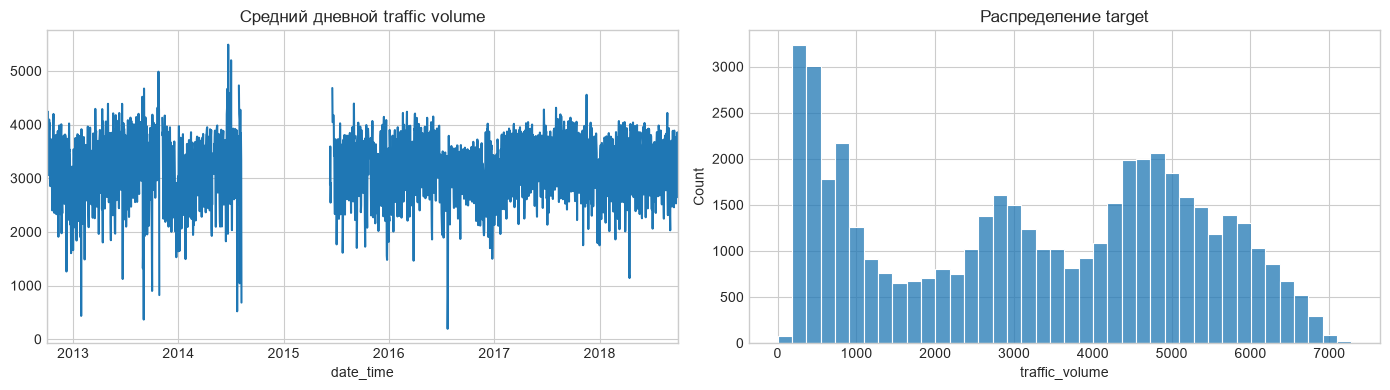

In [2]:
raw = pd.read_csv(DATA_PATH, usecols=['traffic_volume', 'date_time', 'holiday', 'temp'])
raw['date_time'] = pd.to_datetime(raw['date_time'])
raw = raw.sort_values('date_time')
print('Исходная форма:', raw.shape)
print('Дубликатов timestamp:', raw.duplicated('date_time').sum())
gaps = raw.drop_duplicates('date_time')['date_time'].diff().dt.total_seconds().div(3600)
print('Интервалы не равные 1 часу:', (gaps.dropna() != 1).sum())
display(raw.describe(include='all'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw.set_index('date_time')['traffic_volume'].resample('D').mean().plot(ax=axes[0], title='Средний дневной traffic volume')
sns.histplot(raw['traffic_volume'], bins=40, ax=axes[1]); axes[1].set_title('Распределение target')
plt.tight_layout(); plt.show()

## 2. Дубликаты, равномерная сетка и интерполяция

Дубликаты времени возникают из-за нескольких погодных описаний одного часа. Агрегируем числовые признаки средним, а праздник — первым значением, отличным от `None`. Затем строим полный `pd.date_range` с частотой 1 час и линейно интерполируем target и температуру.

In [3]:
def holiday_aggregate(values):
    meaningful = values[values.ne('None') & values.notna()]
    return meaningful.iloc[0] if len(meaningful) else 'None'

hourly = (raw.groupby('date_time', as_index=True)
          .agg(traffic_volume=('traffic_volume', 'mean'),
               temp=('temp', 'mean'), holiday=('holiday', holiday_aggregate)))
full_index = pd.date_range(hourly.index.min(), hourly.index.max(), freq='h')
missing_hours = len(full_index) - len(hourly)
hourly = hourly.reindex(full_index)
hourly.index.name = 'date_time'
hourly[['traffic_volume', 'temp']] = hourly[['traffic_volume', 'temp']].interpolate(method='time', limit_direction='both')
hourly['holiday'] = hourly['holiday'].fillna('None')
assert hourly.index.is_monotonic_increasing and hourly.index.is_unique
assert hourly[['traffic_volume', 'temp', 'holiday']].notna().all().all()
print('Добавлено пропущенных часов:', missing_hours, '| итоговая форма:', hourly.shape)

Добавлено пропущенных часов: 11976 | итоговая форма: (52551, 3)


## 3. Признаки и последние две недели для теста

In [4]:
def make_features(frame):
    result = pd.DataFrame(index=frame.index)
    result['hour'] = frame.index.hour
    result['weekday'] = frame.index.dayofweek
    result['month'] = frame.index.month
    result['dayofyear'] = frame.index.dayofyear
    result['trend'] = (frame.index - hourly.index.min()).total_seconds() / 86400
    result['temp'] = frame['temp'].to_numpy()
    result['is_holiday'] = frame['holiday'].ne('None').astype(int).to_numpy()
    result['hour_sin'] = np.sin(2 * np.pi * result.hour / 24)
    result['hour_cos'] = np.cos(2 * np.pi * result.hour / 24)
    result['week_sin'] = np.sin(2 * np.pi * result.weekday / 7)
    result['week_cos'] = np.cos(2 * np.pi * result.weekday / 7)
    result['year_sin'] = np.sin(2 * np.pi * result.dayofyear / 365.25)
    result['year_cos'] = np.cos(2 * np.pi * result.dayofyear / 365.25)
    return result

TEST_HOURS = 24 * 14
test = hourly.iloc[-TEST_HOURS:].copy()
train_all = hourly.iloc[:-TEST_HOURS].copy()
# Последние два года достаточно отражают актуальный уровень и сохраняют сезонность.
train = train_all.loc[train_all.index >= train_all.index.max() - pd.DateOffset(years=2)].copy()
X_train, y_train = make_features(train), train['traffic_volume']
X_test, y_test = make_features(test), test['traffic_volume']
print('train:', train.index.min(), '—', train.index.max(), len(train))
print('test:', test.index.min(), '—', test.index.max(), len(test))

train: 2016-09-16 23:00:00 — 2018-09-16 23:00:00 17521
test: 2018-09-17 00:00:00 — 2018-09-30 23:00:00 336


## 4. Baseline: среднее по дню недели и часу

In [5]:
profile = train.assign(weekday=train.index.dayofweek, hour=train.index.hour).groupby(['weekday', 'hour'])['traffic_volume'].mean()
baseline_prediction = np.array([profile.loc[(ts.dayofweek, ts.hour)] for ts in test.index])

def metrics_row(name, truth, prediction):
    return {'model': name, 'MAE': mean_absolute_error(truth, prediction),
            'RMSE': mean_squared_error(truth, prediction) ** 0.5,
            'R2': r2_score(truth, prediction)}

scores = [metrics_row('weekday-hour mean', y_test, baseline_prediction)]
display(pd.DataFrame(scores).round(3))

,model,MAE,RMSE,R2
0,weekday-hour mean,200.325,293.656,0.978


## 5. Модели

Ridge получает one-hot час/день/месяц и масштабированные числовые признаки. HistGradientBoosting моделирует нелинейные взаимодействия часа, дня недели, температуры и годовой сезонности. Target-lags из test не используются, поэтому утечки будущих значений нет.

In [6]:
categorical = ['hour', 'weekday', 'month']
numeric = [c for c in X_train.columns if c not in categorical]
ridge = Pipeline([
    ('prepare', ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('num', StandardScaler(), numeric)])),
    ('model', Ridge(alpha=10.0))])
hist = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, max_leaf_nodes=31,
                                     l2_regularization=5, random_state=SEED)
models = {'Ridge': ridge, 'HistGradientBoosting': hist}
predictions = {'weekday-hour mean': baseline_prediction}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    scores.append(metrics_row(name, y_test, predictions[name]))

scores = pd.DataFrame(scores).sort_values('RMSE').reset_index(drop=True)
display(scores.round(3))
scores.to_csv(RESULTS_DIR / 'model_metrics.csv', index=False)

,model,MAE,RMSE,R2
0,weekday-hour mean,200.325,293.656,0.978
1,HistGradientBoosting,205.851,295.615,0.977
2,Ridge,556.913,740.676,0.858


## 6. Визуальное сравнение на test

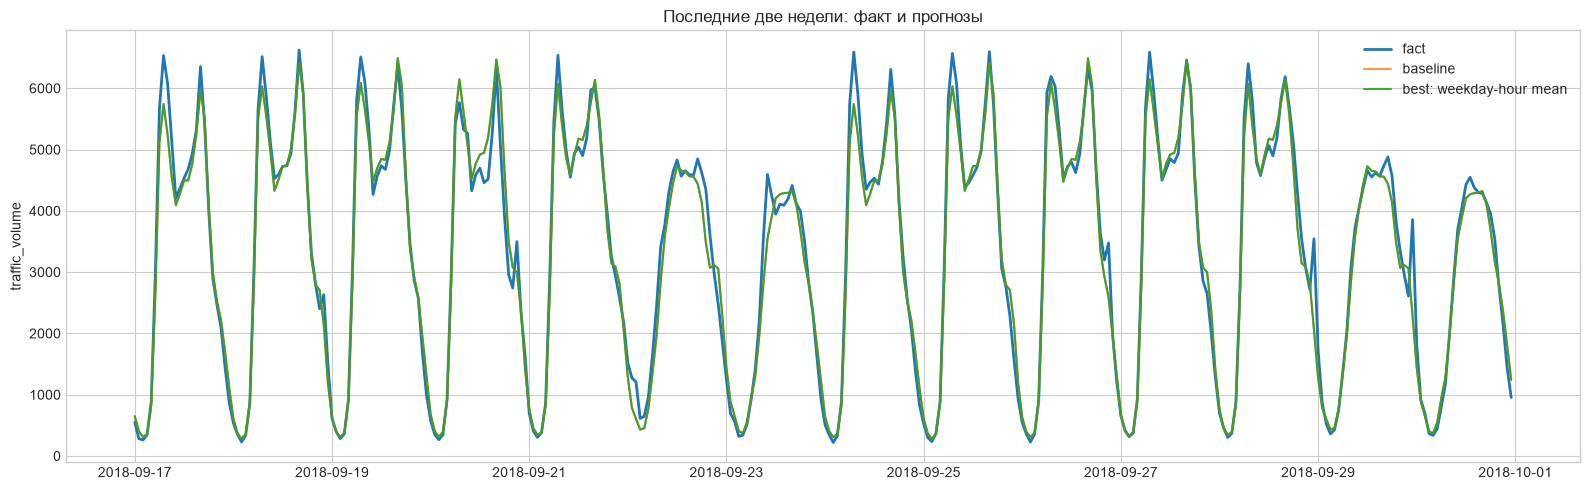

Лучшая модель по RMSE: weekday-hour mean


In [7]:
best_name = scores.iloc[0]['model']
best_prediction = predictions[best_name]
plt.figure(figsize=(16, 5))
plt.plot(test.index, y_test, label='fact', linewidth=2)
plt.plot(test.index, baseline_prediction, label='baseline', alpha=.8)
plt.plot(test.index, best_prediction, label=f'best: {best_name}', alpha=.9)
plt.title('Последние две недели: факт и прогнозы')
plt.ylabel('traffic_volume'); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'test_forecast.png', dpi=160); plt.show()
print('Лучшая модель по RMSE:', best_name)

## 7. Следующая неделя и 95% prediction interval

Будущая температура неизвестна. Используем климатологический прогноз — среднюю температуру последних двух лет для пары `weekday × hour`. Праздники будущей недели считаются отсутствующими. Интервал строится по эмпирическим 2.5% и 97.5% квантилям out-of-sample ошибок лучшей модели на двухнедельном тесте; это prediction interval, а не интервал среднего.

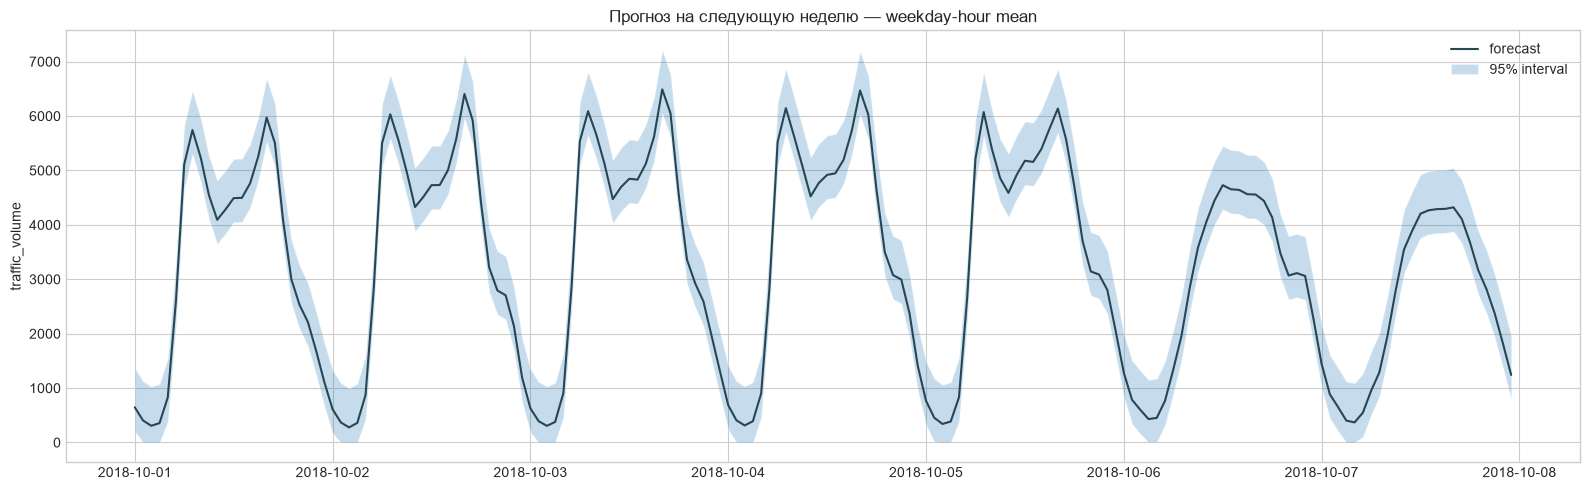

,forecast,lower_95,upper_95
2018-10-01 00:00:00,647.048077,204.834535,1368.300424
2018-10-01 01:00:00,405.009615,0.000000,1126.261962
2018-10-01 02:00:00,307.153846,0.000000,1028.406193
2018-10-01 03:00:00,355.942308,0.000000,1077.194654
2018-10-01 04:00:00,825.721154,383.507612,1546.973500


In [8]:
future_index = pd.date_range(hourly.index.max() + pd.Timedelta(hours=1), periods=24 * 7, freq='h')
temp_profile = train.assign(weekday=train.index.dayofweek, hour=train.index.hour).groupby(['weekday', 'hour'])['temp'].mean()
future = pd.DataFrame(index=future_index)
future['temp'] = [temp_profile.loc[(ts.dayofweek, ts.hour)] for ts in future_index]
future['holiday'] = 'None'
X_future = make_features(future)

if best_name == 'weekday-hour mean':
    future_prediction = np.array([profile.loc[(ts.dayofweek, ts.hour)] for ts in future_index])
else:
    # Переобучаем выбранную модель на всей истории до конца test.
    final_frame = hourly.loc[hourly.index >= hourly.index.max() - pd.DateOffset(years=2)]
    final_model = models[best_name]
    final_model.fit(make_features(final_frame), final_frame['traffic_volume'])
    future_prediction = final_model.predict(X_future)

residuals = y_test.to_numpy() - best_prediction
lower_error, upper_error = np.quantile(residuals, [0.025, 0.975])
forecast = pd.DataFrame({'forecast': future_prediction,
                         'lower_95': np.maximum(0, future_prediction + lower_error),
                         'upper_95': future_prediction + upper_error}, index=future_index)
forecast.to_csv(RESULTS_DIR / 'next_week_forecast.csv')

plt.figure(figsize=(16, 5))
plt.plot(forecast.index, forecast.forecast, label='forecast', color='#264653')
plt.fill_between(forecast.index, forecast.lower_95, forecast.upper_95, alpha=.25, label='95% interval')
plt.title(f'Прогноз на следующую неделю — {best_name}')
plt.ylabel('traffic_volume'); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'next_week_forecast.png', dpi=160); plt.show()
display(forecast.head())

## Выводы

Очистка подтвердила обе проблемы из задания: дубликаты timestamps и пропуски в почасовой сетке. Сильный baseline отражает недельную и суточную сезонность. ML-модель дополнительно использует температуру, праздник, годовую сезонность и тренд. Сравнение проводится на одном и том же последнем 14-дневном отрезке по MAE, RMSE и R².

Главные ограничения прогноза — неизвестная будущая погода, редкие праздники и изменение режима трафика. Эмпирический prediction interval учитывает типичную ошибку на отложенных данных, но не гарантирует идеальной калибровки на экстремальных событиях.